<a href="https://colab.research.google.com/github/2303A51621/2303A51621/blob/main/Project%20arvr.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install pandas numpy matplotlib scikit-learn openpyxl torch

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import TensorDataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from google.colab import files
import io

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("PyTorch:", torch.__version__)

Device: cpu
PyTorch: 2.11.0+cpu


In [6]:
uploaded = files.upload()

file_name = next(iter(uploaded))

df = pd.read_excel(
    io.BytesIO(uploaded[file_name])
)

print("Dataset uploaded successfully!")

display(df.head(10))

print("\nDataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

Saving Data.xlsx to Data (1).xlsx
Dataset uploaded successfully!


,PM2.5,RH,WD,SR,BP,AT,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12
0,355,89,152,7.0,726,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,355,89,156,7.0,726,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,355,89,168,7.0,726,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,342,89,167,7.0,726,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,342,89,171,7.0,726,13,NaN,NaN,NaN,NaN,NaN,NaN,Delhi
5,342,89,139,7.0,726,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,342,89,166,7.0,726,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,272,90,154,7.0,726,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,272,90,157,7.0,726,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,272,90,174,7.0,726,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Dataset Shape: (2183, 13)

Column Names:
['PM2.5', 'RH', 'WD', 'SR', 'BP', 'AT', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12']


In [7]:
features = [
    "PM2.5",
    "RH",
    "WD",
    "SR",
    "BP",
    "AT"
]

# Select required columns
data = df[features].copy()

# Convert all columns into numeric values
for col in features:
    data[col] = pd.to_numeric(
        data[col],
        errors="coerce"
    )

# Replace infinite values
data = data.replace(
    [np.inf, -np.inf],
    np.nan
)

# Fill missing values
data = data.interpolate(
    method="linear",
    limit_direction="both"
)

data = data.dropna().reset_index(drop=True)

print("Preprocessing completed!")

print("Final Dataset Shape:", data.shape)

display(data.head())

Preprocessing completed!
Final Dataset Shape: (2183, 6)


,PM2.5,RH,WD,SR,BP,AT
0,355,89,152,7.0,726,13
1,355,89,156,7.0,726,13
2,355,89,168,7.0,726,13
3,342,89,167,7.0,726,13
4,342,89,171,7.0,726,13


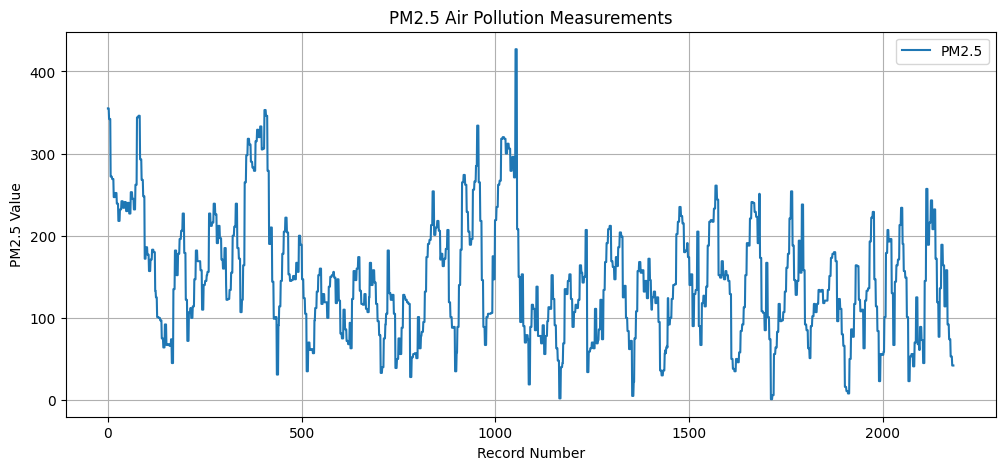

In [8]:
plt.figure(figsize=(12, 5))

plt.plot(
    data["PM2.5"].values,
    label="PM2.5"
)

plt.title("PM2.5 Air Pollution Measurements")

plt.xlabel("Record Number")

plt.ylabel("PM2.5 Value")

plt.legend()

plt.grid(True)

plt.show()

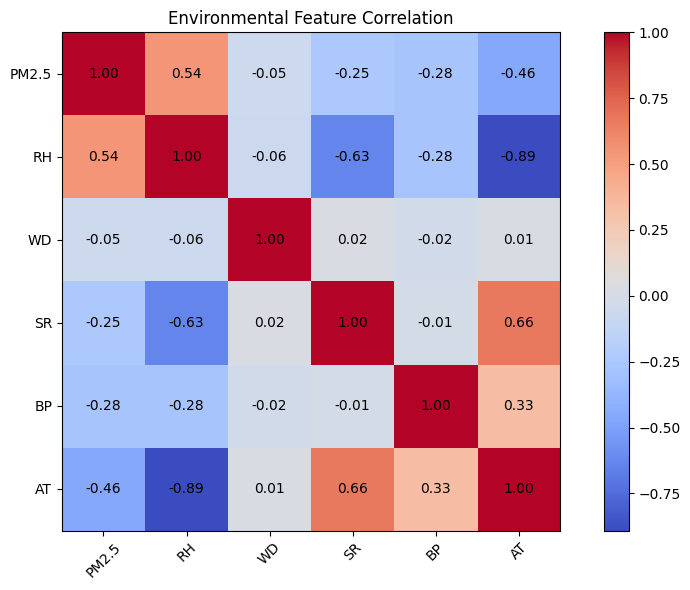

In [9]:
plt.figure(figsize=(9, 6))

correlation = data.corr()

plt.imshow(
    correlation,
    cmap="coolwarm",
    interpolation="nearest"
)

plt.colorbar()

plt.xticks(
    range(len(features)),
    features,
    rotation=45
)

plt.yticks(
    range(len(features)),
    features
)

plt.title("Environmental Feature Correlation")

for i in range(len(features)):
    for j in range(len(features)):
        plt.text(
            j, i,
            f"{correlation.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.tight_layout()

plt.show()

In [10]:
sequence_length = 12

values = data[features].values.astype(np.float32)

n = len(values)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

# Fit scalers only on training data
feature_scaler = StandardScaler()

feature_scaler.fit(
    values[:train_end]
)

scaled_features = feature_scaler.transform(
    values
)

target_scaler = StandardScaler()

target_scaler.fit(
    values[:train_end, 0].reshape(-1, 1)
)

scaled_target = target_scaler.transform(
    values[:, 0].reshape(-1, 1)
).flatten()

# Create sequences
X = []
y = []
target_indices = []

for i in range(n - sequence_length):

    X.append(
        scaled_features[i:i + sequence_length]
    )

    y.append(
        scaled_target[i + sequence_length]
    )

    target_indices.append(
        i + sequence_length
    )

X = np.array(X, dtype=np.float32)

y = np.array(y, dtype=np.float32)

target_indices = np.array(target_indices)

# Chronological split
train_mask = target_indices < train_end

val_mask = (
    (target_indices >= train_end) &
    (target_indices < val_end)
)

test_mask = target_indices >= val_end

X_train = X[train_mask]
y_train = y[train_mask]

X_val = X[val_mask]
y_val = y[val_mask]

X_test = X[test_mask]
y_test = y[test_mask]

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (1516, 12, 6)
Validation: (327, 12, 6)
Testing: (328, 12, 6)


In [11]:
X_train = torch.tensor(X_train, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.float32)

X_val = torch.tensor(X_val, dtype=torch.float32)
y_val = torch.tensor(y_val, dtype=torch.float32)

X_test = torch.tensor(X_test, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.float32)

train_dataset = TensorDataset(
    X_train,
    y_train
)

val_dataset = TensorDataset(
    X_val,
    y_val
)

test_dataset = TensorDataset(
    X_test,
    y_test
)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

print("PyTorch datasets prepared successfully!")

PyTorch datasets prepared successfully!


In [12]:
class ClockworkRNN(nn.Module):

    def __init__(
        self,
        input_size=6,
        module_size=32
    ):

        super().__init__()

        self.periods = [1, 2, 4, 8]

        self.module_size = module_size

        self.input_layers = nn.ModuleList()

        self.recurrent_layers = nn.ModuleList()

        for i in range(4):

            self.input_layers.append(
                nn.Linear(
                    input_size,
                    module_size
                )
            )

            self.recurrent_layers.append(
                nn.Linear(
                    (i + 1) * module_size,
                    module_size
                )
            )

        self.output_layer = nn.Linear(
            4 * module_size,
            1
        )

    def forward(self, x):

        batch_size = x.size(0)

        sequence_length = x.size(1)

        hidden = [
            torch.zeros(
                batch_size,
                self.module_size,
                device=x.device
            )
            for _ in range(4)
        ]

        for t in range(sequence_length):

            current_input = x[:, t, :]

            for i in range(4):

                if t % self.periods[i] == 0:

                    previous_hidden = torch.cat(
                        hidden[:i + 1],
                        dim=1
                    )

                    hidden[i] = torch.tanh(
                        self.input_layers[i](current_input)
                        +
                        self.recurrent_layers[i](
                            previous_hidden
                        )
                    )

        final_hidden = torch.cat(
            hidden,
            dim=1
        )

        prediction = self.output_layer(
            final_hidden
        )

        return prediction.squeeze(-1)


model = ClockworkRNN(
    input_size=6,
    module_size=32
).to(device)

print(model)

ClockworkRNN(
  (input_layers): ModuleList(
    (0-3): 4 x Linear(in_features=6, out_features=32, bias=True)
  )
  (recurrent_layers): ModuleList(
    (0): Linear(in_features=32, out_features=32, bias=True)
    (1): Linear(in_features=64, out_features=32, bias=True)
    (2): Linear(in_features=96, out_features=32, bias=True)
    (3): Linear(in_features=128, out_features=32, bias=True)
  )
  (output_layer): Linear(in_features=128, out_features=1, bias=True)
)


In [13]:
criterion = nn.MSELoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 40

print("Loss Function: Mean Squared Error")
print("Optimizer: Adam")
print("Learning Rate: 0.001")
print("Epochs:", epochs)

Loss Function: Mean Squared Error
Optimizer: Adam
Learning Rate: 0.001
Epochs: 40


In [14]:
train_losses = []
val_losses = []

best_val_loss = float("inf")

for epoch in range(epochs):

    model.train()

    running_loss = 0

    for inputs, targets in train_loader:

        inputs = inputs.to(device)

        targets = targets.to(device)

        optimizer.zero_grad()

        outputs = model(inputs)

        loss = criterion(
            outputs,
            targets
        )

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    train_loss = running_loss / len(train_loader)

    # Validation
    model.eval()

    validation_loss = 0

    with torch.no_grad():

        for inputs, targets in val_loader:

            inputs = inputs.to(device)

            targets = targets.to(device)

            outputs = model(inputs)

            loss = criterion(
                outputs,
                targets
            )

            validation_loss += loss.item()

    val_loss = validation_loss / len(val_loader)

    train_losses.append(train_loss)

    val_losses.append(val_loss)

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(
            model.state_dict(),
            "best_clockwork_rnn.pth"
        )

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Training Loss: {train_loss:.5f} "
        f"Validation Loss: {val_loss:.5f}"
    )

# Restore best model
model.load_state_dict(
    torch.load(
        "best_clockwork_rnn.pth",
        map_location=device,
        weights_only=True
    )
)

print("\nClockwork RNN training completed!")

Epoch [1/40] Training Loss: 0.33132 Validation Loss: 0.15564
Epoch [2/40] Training Loss: 0.13352 Validation Loss: 0.08541
Epoch [3/40] Training Loss: 0.10812 Validation Loss: 0.08097
Epoch [4/40] Training Loss: 0.09361 Validation Loss: 0.07701
Epoch [5/40] Training Loss: 0.08612 Validation Loss: 0.06889
Epoch [6/40] Training Loss: 0.07760 Validation Loss: 0.06655
Epoch [7/40] Training Loss: 0.07656 Validation Loss: 0.06615
Epoch [8/40] Training Loss: 0.06933 Validation Loss: 0.06721
Epoch [9/40] Training Loss: 0.06607 Validation Loss: 0.06599
Epoch [10/40] Training Loss: 0.06450 Validation Loss: 0.06536
Epoch [11/40] Training Loss: 0.06259 Validation Loss: 0.06612
Epoch [12/40] Training Loss: 0.06139 Validation Loss: 0.06001
Epoch [13/40] Training Loss: 0.05779 Validation Loss: 0.06222
Epoch [14/40] Training Loss: 0.05756 Validation Loss: 0.05751
Epoch [15/40] Training Loss: 0.05619 Validation Loss: 0.06127
Epoch [16/40] Training Loss: 0.05497 Validation Loss: 0.05862
Epoch [17/40] Tra

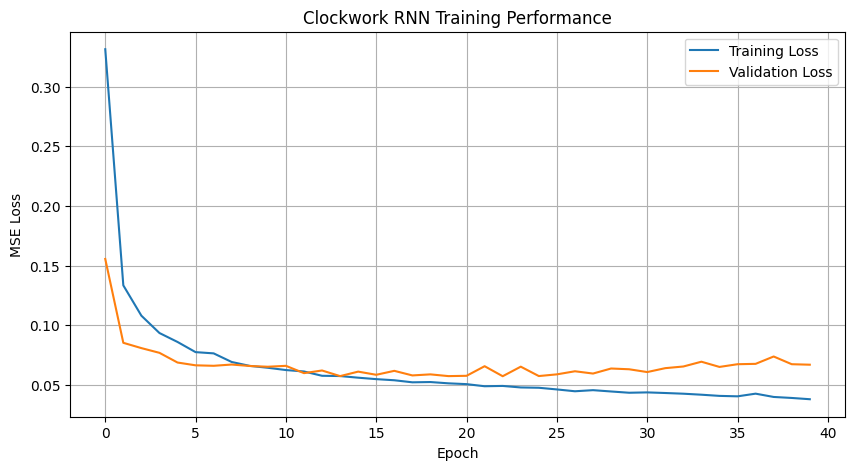

In [15]:
plt.figure(figsize=(10, 5))

plt.plot(
    train_losses,
    label="Training Loss"
)

plt.plot(
    val_losses,
    label="Validation Loss"
)

plt.title("Clockwork RNN Training Performance")

plt.xlabel("Epoch")

plt.ylabel("MSE Loss")

plt.legend()

plt.grid(True)

plt.show()

In [16]:
model.eval()

predictions = []
actual_values = []

with torch.no_grad():

    for inputs, targets in test_loader:

        inputs = inputs.to(device)

        outputs = model(inputs)

        predictions.extend(
            outputs.cpu().numpy()
        )

        actual_values.extend(
            targets.numpy()
        )

# Convert predictions back to original PM2.5 scale
predictions = target_scaler.inverse_transform(
    np.array(predictions).reshape(-1, 1)
).flatten()

actual_values = target_scaler.inverse_transform(
    np.array(actual_values).reshape(-1, 1)
).flatten()

mae = mean_absolute_error(
    actual_values,
    predictions
)

rmse = np.sqrt(
    mean_squared_error(
        actual_values,
        predictions
    )
)

r2 = r2_score(
    actual_values,
    predictions
)

print("========== MODEL EVALUATION ==========")

print("MAE:", round(mae, 3))

print("RMSE:", round(rmse, 3))

print("R2 Score:", round(r2, 4))

print("======================================")

========== MODEL EVALUATION ==========
MAE: 15.351
RMSE: 22.328
R2 Score: 0.8674


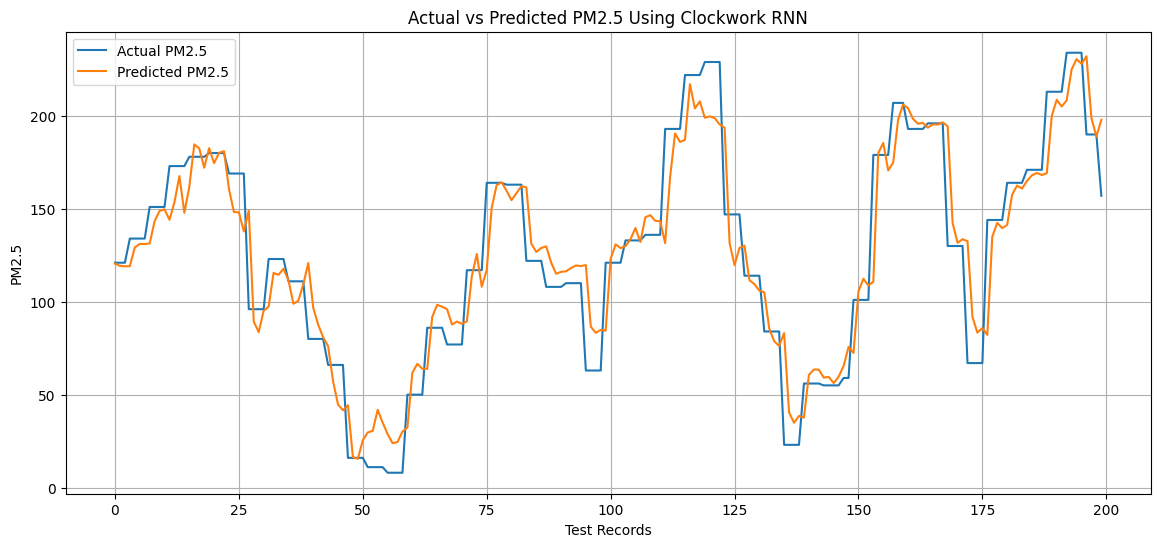

In [17]:
plt.figure(figsize=(14, 6))

plt.plot(
    actual_values[:200],
    label="Actual PM2.5"
)

plt.plot(
    predictions[:200],
    label="Predicted PM2.5"
)

plt.title("Actual vs Predicted PM2.5 Using Clockwork RNN")

plt.xlabel("Test Records")

plt.ylabel("PM2.5")

plt.legend()

plt.grid(True)

plt.show()

In [18]:
def predict_next_pm25():

    model.eval()

    latest_data = scaled_features[-sequence_length:]

    input_tensor = torch.tensor(
        latest_data,
        dtype=torch.float32
    ).unsqueeze(0).to(device)

    with torch.no_grad():

        output = model(input_tensor)

    predicted_scaled = output.cpu().numpy().reshape(-1, 1)

    predicted_pm25 = target_scaler.inverse_transform(
        predicted_scaled
    )[0][0]

    return max(0, float(predicted_pm25))


future_pm25 = predict_next_pm25()

print("================================")
print("NEXT PM2.5 PREDICTION")
print("================================")

print("Predicted PM2.5:", round(future_pm25, 2))

print("================================")

NEXT PM2.5 PREDICTION
Predicted PM2.5: 54.74


In [19]:
def get_environment(pm25):

    if pm25 <= 30:

        return {
            "level": "CLEAN ENVIRONMENT",
            "description": "Clear sky and clean virtual surroundings",
            "effect": "No pollution haze",
            "color": "lightblue"
        }

    elif pm25 <= 60:

        return {
            "level": "SATISFACTORY",
            "description": "Slight pollution in the environment",
            "effect": "Light haze",
            "color": "lightgreen"
        }

    elif pm25 <= 90:

        return {
            "level": "MODERATE POLLUTION",
            "description": "Visible pollution in virtual surroundings",
            "effect": "Moderate haze",
            "color": "yellow"
        }

    elif pm25 <= 120:

        return {
            "level": "POOR AIR QUALITY",
            "description": "Heavy haze in the virtual environment",
            "effect": "Strong haze",
            "color": "orange"
        }

    elif pm25 <= 250:

        return {
            "level": "VERY POOR AIR QUALITY",
            "description": "Highly polluted virtual environment",
            "effect": "Dense haze",
            "color": "red"
        }

    else:

        return {
            "level": "SEVERE POLLUTION",
            "description": "Extremely polluted virtual surroundings",
            "effect": "Very dense haze",
            "color": "darkred"
        }


environment = get_environment(future_pm25)

print("========== AR/VR ENVIRONMENT ==========")

print("Predicted PM2.5:", round(future_pm25, 2))

print("Environment:", environment["level"])

print("Description:", environment["description"])

print("Visual Effect:", environment["effect"])

print("=======================================")

========== AR/VR ENVIRONMENT ==========
Predicted PM2.5: 54.74
Environment: SATISFACTORY
Description: Slight pollution in the environment
Visual Effect: Light haze


In [20]:
!pip install plotly

In [21]:
import plotly.graph_objects as go

environment = get_environment(future_pm25)

fig = go.Figure()

# Create virtual buildings
buildings = [
    (0, 0, 2, 3, 5),
    (5, 0, 2, 3, 8),
    (10, 0, 2, 3, 6),
    (0, 5, 2, 3, 7),
    (5, 5, 2, 3, 4),
    (10, 5, 2, 3, 9)
]

for x, y, width, depth, height in buildings:

    fig.add_trace(
        go.Mesh3d(
            x=[
                x, x+width, x+width, x,
                x, x+width, x+width, x
            ],
            y=[
                y, y, y+depth, y+depth,
                y, y, y+depth, y+depth
            ],
            z=[
                0, 0, 0, 0,
                height, height, height, height
            ],
            i=[0, 0, 0, 1, 1, 2, 4, 4, 5, 3, 3, 6],
            j=[1, 2, 3, 2, 5, 3, 5, 6, 6, 2, 6, 7],
            k=[4, 4, 4, 4, 6, 7, 6, 7, 7, 7, 7, 7],
            color="gray",
            opacity=0.85,
            showscale=False
        )
    )

fig.update_layout(
    title=(
        "AR/VR Virtual City - " +
        environment["level"] +
        f" | PM2.5: {future_pm25:.2f}"
    ),
    scene=dict(
        xaxis_title="X Position",
        yaxis_title="Y Position",
        zaxis_title="Building Height",
        bgcolor=environment["color"],
        aspectmode="data"
    ),
    width=900,
    height=650
)

fig.show()

In [22]:
print("\n")
print("============================================")
print(" CLOCKWORK RNN - AR/VR PROJECT DASHBOARD")
print("============================================")

print("\nMODEL INFORMATION")

print("Model: Clockwork Recurrent Neural Network")

print("Input Features: 6")

print("Sequence Length: 12")

print("Clock Periods: 1, 2, 4, 8")

print("\nPREDICTION RESULTS")

print("Predicted PM2.5:", round(future_pm25, 2))

print("MAE:", round(mae, 3))

print("RMSE:", round(rmse, 3))

print("R2 Score:", round(r2, 4))

print("\nAR/VR VISUALIZATION")

print("Air Quality:", environment["level"])

print("Virtual Effect:", environment["effect"])

print("\nPROJECT STATUS: COMPLETED")

print("============================================")



 CLOCKWORK RNN - AR/VR PROJECT DASHBOARD

MODEL INFORMATION
Model: Clockwork Recurrent Neural Network
Input Features: 6
Sequence Length: 12
Clock Periods: 1, 2, 4, 8

PREDICTION RESULTS
Predicted PM2.5: 54.74
MAE: 15.351
RMSE: 22.328
R2 Score: 0.8674

AR/VR VISUALIZATION
Air Quality: SATISFACTORY
Virtual Effect: Light haze

PROJECT STATUS: COMPLETED


In [23]:
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "feature_scaler_mean": feature_scaler.mean_,
        "feature_scaler_scale": feature_scaler.scale_,
        "target_scaler_mean": target_scaler.mean_,
        "target_scaler_scale": target_scaler.scale_,
        "features": features,
        "sequence_length": sequence_length
    },
    "Clockwork_RNN_ARVR_Model.pth"
)

print("Model saved successfully!")

files.download(
    "Clockwork_RNN_ARVR_Model.pth"
)

Model saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>